In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 3.6 — Subgroup embedding

Source: SMSA version 7.8 (2026-11-05), `smsa.pdf`. This notebook translates the named formulas; it does not replace their discussion in SMSA. Native DisCoPy figures below read **top to bottom**, whereas SMSA reads bottom to top. Tensor factors retain their left-to-right order. `f >> g` means $g\circ f$. Tensor arrays list input axes before output axes; a conventional column matrix is supplied transposed. Checks print computed objects and residuals and do not stop execution on a failed equality.

Equations (3.77)–(3.78). We instantiate $\mathbb Z_2\hookrightarrow\mathbb Z_4$ by $h\mapsto2h$ and extend linearly to group algebras. This changes set maps into linear maps while preserving the displayed multiplication compatibility. Rectangular labeled coupons replace SMSA’s special embedding symbol.

In [1]:
from discopy import symmetric, tensor
import numpy as np

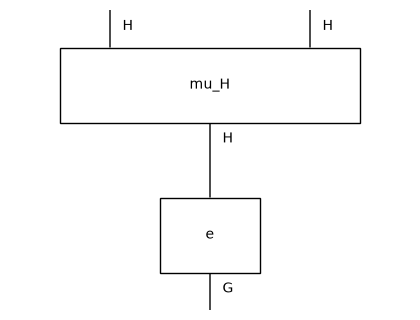

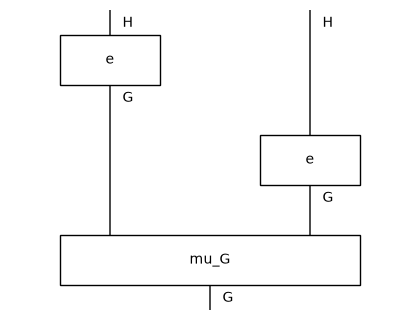

In [2]:
H, G = symmetric.Ty('H'), symmetric.Ty('G')
e = symmetric.Box('e', H, G)
mH = symmetric.Box('mu_H', H @ H, H)
mG = symmetric.Box('mu_G', G @ G, G)
left = mH >> e
right = (e @ e) >> mG
left.draw(figsize=(4, 3))
right.draw(figsize=(4, 3))

In [3]:
embedding = np.array([[1,0,0,0],[0,0,1,0]])
product_H = np.array([int(k == (i+j)%2) for i in range(2) for j in range(2) for k in range(2)]).reshape(2,2,2)
product_G = np.array([int(k == (i+j)%4) for i in range(4) for j in range(4) for k in range(4)]).reshape(4,4,4)
F = tensor.Functor({H: tensor.Dim(2), G: tensor.Dim(4)}, {e: embedding, mH: product_H, mG: product_G}, dom=symmetric.Category, dtype=int)
print('(3.78): first two axes are input subgroup labels; last is the output group label')
print('mu_H then e =', F(left).array)
print('e tensor e then mu_G =', F(right).array)
print('difference =', F(left).array - F(right).array)
print('equal =', F(left) == F(right))

(3.78): first two axes are input subgroup labels; last is the output group label
mu_H then e = [[[1 0 0 0]
  [0 0 1 0]]

 [[0 0 1 0]
  [1 0 0 0]]]
e tensor e then mu_G = [[[1 0 0 0]
  [0 0 1 0]]

 [[0 0 1 0]
  [1 0 0 0]]]
difference = [[[0 0 0 0]
  [0 0 0 0]]

 [[0 0 0 0]
  [0 0 0 0]]]
equal = True


### Direct product: embedding and projection, (3.82)–(3.85)

Example 3.6.13 embeds $H$ into $G=H\times H'$ by $h\mapsto(h,e_{H'})$, and Remark 3.6.14 projects back by $(h,h')\mapsto h$. Their composite (3.84) is the identity on $H$, drawn in (3.85) with an upward triangle for the embedding and a downward triangle for the projection on one $H$ wire. Here both are labelled rectangles `e` and `r`. The example is $H=H'=\mathbb Z_2$, so $G=\mathbb Z_2\times\mathbb Z_2$ with basis order $(0,0),(0,1),(1,0),(1,1)$; the type `H` and its product `mu_H` are those of the cells above. The other composite, `r >> e`, is a projector of rank $2$ and not the identity, which is why (3.85) has only the one equation. Warning 3.6.16 says that a general subgroup has no such projection; the direct product is the special case where it exists.

(3.82) e, rows h, columns (h,h') in the order [(0, 0), (0, 1), (1, 0), (1, 1)] :
 [[1 0 0 0]
 [0 0 1 0]]
(3.83) r, rows (h,h'), columns h:
 [[1 0]
 [1 0]
 [0 1]
 [0 1]]
(3.84) r after e, array [h_in, h_out]:
 [[1 0]
 [0 1]] 
equals the identity on H: True
e after r, array [(h,h')_in, (h,h')_out]:
 [[1 0 0 0]
 [1 0 0 0]
 [0 0 1 0]
 [0 0 1 0]]
Idempotent: True ; equals the identity on G (expected False): False ; rank: 2
e respects products as in (3.78): True
r respects products: True


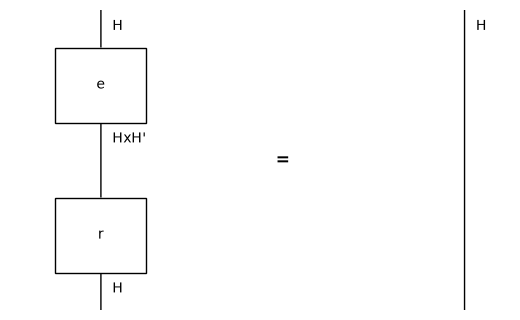

In [4]:
from discopy.drawing import Equation
P = symmetric.Ty("HxH'")
e_P = symmetric.Box('e', H, P)
r_P = symmetric.Box('r', P, H)
mP = symmetric.Box("mu_HxH'", P @ P, P)
pairs = [(h, k) for h in range(2) for k in range(2)]
embed_P = np.array([[int(pairs[n] == (h, 0)) for n in range(4)] for h in range(2)])
project_P = np.array([[int(pairs[n][0] == h) for h in range(2)] for n in range(4)])
product_P = np.array([[[int(pairs[c] == ((pairs[a][0] + pairs[b][0]) % 2, (pairs[a][1] + pairs[b][1]) % 2)) for c in range(4)] for b in range(4)] for a in range(4)])
F_P = tensor.Functor({H: tensor.Dim(2), P: tensor.Dim(4)}, {e_P: embed_P, r_P: project_P, mP: product_P, mH: product_H}, dom=symmetric.Category, dtype=int)
Equation(e_P >> r_P, symmetric.Id(H), symbol='=').draw(figsize=(5, 3))
print('(3.82) e, rows h, columns (h,h\') in the order', pairs, ':\n', embed_P)
print('(3.83) r, rows (h,h\'), columns h:\n', project_P)
print('(3.84) r after e, array [h_in, h_out]:\n', F_P(e_P >> r_P).array, '\nequals the identity on H:', np.array_equal(F_P(e_P >> r_P).array, np.eye(2, dtype=int)))
back = F_P(r_P >> e_P).array
print('e after r, array [(h,h\')_in, (h,h\')_out]:\n', back)
print('Idempotent:', np.array_equal(back @ back, back), '; equals the identity on G (expected False):', np.array_equal(back, np.eye(4, dtype=int)), '; rank:', np.linalg.matrix_rank(back))
print('e respects products as in (3.78):', F_P(mH >> e_P) == F_P((e_P @ e_P) >> mP))
print('r respects products:', F_P(mP >> r_P) == F_P((r_P @ r_P) >> mH))


**Scope.** Both the subgroup embedding $\mathbb Z_2\hookrightarrow\mathbb Z_4$ above and the direct-product pair are checked on their displayed arrays only. The adjoint action of Task 3.6.25 is left to the reader.